In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/price_history.csv")

df.head()

,product_id,product_name,category,brand,platform,date,price_inr,mrp_inr,currency,data_source
0,P001,Wireless Headphones,Electronics,SoundMax,Store A,2026-04-30,5210,5999,INR,simulated
1,P001,Wireless Headphones,Electronics,SoundMax,Store A,2026-05-01,5250,5999,INR,simulated
2,P001,Wireless Headphones,Electronics,SoundMax,Store A,2026-05-02,5310,5999,INR,simulated
3,P001,Wireless Headphones,Electronics,SoundMax,Store A,2026-05-03,5280,5999,INR,simulated
4,P001,Wireless Headphones,Electronics,SoundMax,Store A,2026-05-04,5310,5999,INR,simulated


In [2]:
print("Dataset shape:", df.shape)

df.info()

df.describe()

Dataset shape: (5400, 10)
<class 'pandas.DataFrame'>
RangeIndex: 5400 entries, 0 to 5399
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   product_id    5400 non-null   str  
 1   product_name  5400 non-null   str  
 2   category      5400 non-null   str  
 3   brand         5400 non-null   str  
 4   platform      5400 non-null   str  
 5   date          5400 non-null   str  
 6   price_inr     5400 non-null   int64
 7   mrp_inr       5400 non-null   int64
 8   currency      5400 non-null   str  
 9   data_source   5400 non-null   str  
dtypes: int64(2), str(8)
memory usage: 779.7 KB


,price_inr,mrp_inr
count,5400.000000,5400.000000
mean,5784.998148,7512.333333
std,5146.281448,6229.206046
min,1110.000000,1599.000000
25%,2170.000000,2999.000000
50%,3960.000000,5249.000000
75%,7520.000000,8999.000000
max,22990.000000,24999.000000


In [3]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique products:", df["product_id"].nunique())

Missing values:
product_id      0
product_name    0
category        0
brand           0
platform        0
date            0
price_inr       0
mrp_inr         0
currency        0
data_source     0
dtype: int64

Duplicate rows: 0

Unique products: 30


In [4]:
clean_df = df.copy()

clean_df["date"] = pd.to_datetime(
    clean_df["date"],
    errors="coerce"
)

clean_df["price_inr"] = pd.to_numeric(
    clean_df["price_inr"],
    errors="coerce"
)

clean_df["product_name"] = (
    clean_df["product_name"]
    .astype("string")
    .str.strip()
)

clean_df = clean_df.dropna(
    subset=[
        "product_id",
        "product_name",
        "date",
        "price_inr",
    ]
)

clean_df = clean_df[
    clean_df["price_inr"] > 0
]

clean_df = clean_df.drop_duplicates(
    subset=["product_id", "date", "platform"]
)

clean_df = clean_df.sort_values(
    ["product_id", "date"]
).reset_index(drop=True)

print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(clean_df))

Rows before cleaning: 5400
Rows after cleaning: 5400


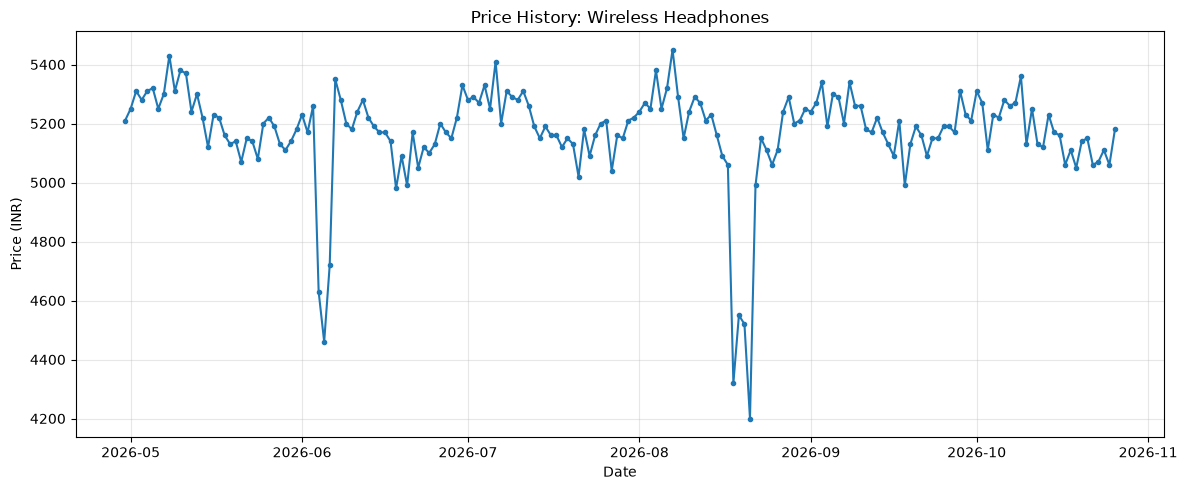

In [5]:
product_id = clean_df["product_id"].iloc[0]

product = clean_df[
    clean_df["product_id"] == product_id
]

plt.figure(figsize=(12, 5))

plt.plot(
    product["date"],
    product["price_inr"],
    marker=".",
)

plt.title(
    f"Price History: {product['product_name'].iloc[0]}"
)

plt.xlabel("Date")
plt.ylabel("Price (INR)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
prices = product["price_inr"]

q1 = prices.quantile(0.25)
q3 = prices.quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

anomalies = product[
    (product["price_inr"] < lower_bound)
    | (product["price_inr"] > upper_bound)
]

print("IQR lower bound:", lower_bound)
print("IQR upper bound:", upper_bound)

anomalies[["date", "price_inr"]]

IQR lower bound: 4935.0
IQR upper bound: 5455.0


,date,price_inr
35,2026-06-04,4630
36,2026-06-05,4460
37,2026-06-06,4720
110,2026-08-18,4320
111,2026-08-19,4550
112,2026-08-20,4520
113,2026-08-21,4200


,count,mean,median,min,max
category,,,,,
Accessories,1620,2630.52,2680.0,1110,4870
Electronics,2160,7528.16,5200.0,2410,22990
Home Appliances,1620,6615.26,4180.0,1110,19490


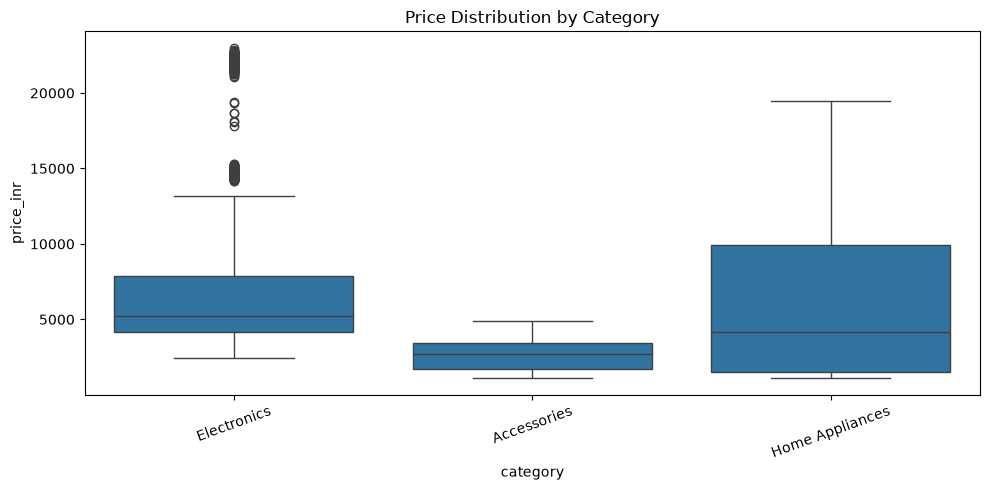

In [7]:
category_summary = (
    clean_df.groupby("category")["price_inr"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(category_summary)

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=clean_df,
    x="category",
    y="price_inr",
)

plt.title("Price Distribution by Category")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()